# Project 1: Segmenting Wholesale Customers by Spending Behaviour

**Course:** DSC8307 Data Mining, Modelling and Analytics
**Task:** Segment wholesale customers by spending behaviour and recommend how the distributor could serve each segment differently.

**Data source:** `wholesale-customers.csv`, UCI Machine Learning Repository, *Wholesale customers* dataset. M. Cardoso (2014), *Wholesale customers*, UCI Machine Learning Repository. 440 clients of a wholesale distributor in Portugal, with each client's annual spending in monetary units (m.u.) on six product categories, plus their sales channel and region.

**Contents:** 1. Loading and inspecting · 2. Data preparation · 3. Cluster tendency · 4. Partitioning (k-means) · 5. Hierarchical clustering · 6. Density-based clustering · 7. Comparing the three approaches · 8. Naming the segments and recommendations · 9. Sensitivity checks · 10. Conclusions and limitations · References

**To run:** put `wholesale-customers.csv` in the same folder as this notebook and install the packages in `requirements.txt`.


## 1. Loading and inspecting the data

In [24]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")

# Colours used for the clusters throughout (cluster 0, 1, 2) and grey for "noise" points
CLUSTER_COLOURS = ["steelblue", "darkorange", "seagreen"]
NOISE_COLOUR = "grey"

df = pd.read_csv("wholesale-customers.csv")
SPEND = ["Fresh", "Milk", "Grocery", "Frozen", "Detergents_Paper", "Delicatessen"]   # the six spending columns

print(df.shape)
print("Missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
df.head()

(440, 8)
Missing values: 0
Duplicate rows: 0


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


In [25]:
# Labels for the two nominal columns (from the dataset documentation)
df["Channel_name"] = df["Channel"].map({1: "HoReCa", 2: "Retail"})
df["Region_name"] = df["Region"].map({1: "Lisbon", 2: "Oporto", 3: "Other"})

print(df["Channel_name"].value_counts(), "\n")
print(df["Region_name"].value_counts(), "\n")

summary = df[SPEND].describe().T[["mean", "50%", "min", "max"]].rename(columns={"50%": "median"})
summary["skewness"] = df[SPEND].skew()
summary["customers below 50 m.u."] = (df[SPEND] < 50).sum()
summary.round(1)

Channel_name
HoReCa    298
Retail    142
Name: count, dtype: int64 

Region_name
Other     316
Lisbon     77
Oporto     47
Name: count, dtype: int64 



,mean,median,min,max,skewness,customers below 50 m.u.
Fresh,12000.3,8504.0,3.0,112151.0,2.6,6
Milk,5796.3,3627.0,55.0,73498.0,4.1,0
Grocery,7951.3,4755.5,3.0,92780.0,3.6,1
Frozen,3071.9,1526.0,25.0,60869.0,5.9,6
Detergents_Paper,2881.5,816.5,3.0,40827.0,3.6,17
Delicatessen,1524.9,965.5,3.0,47943.0,11.2,15


**Observations:**

- 440 customers, 6 spending columns and 2 nominal columns (Channel, Region); no missing values and no duplicate rows
- **Channel:** 298 HoReCa (hotels, restaurants, cafés) and 142 Retail customers
- **Region:** 316 "Other", 77 Lisbon and 47 Oporto, so "Other" dominates
- every spending category is strongly **right-skewed** (skewness from 2.6 for Fresh to 11.2 for Delicatessen). Means sit well above medians (Fresh: mean 12,000 vs median 8,504 m.u.), and a few customers spend very large amounts (up to 112,151 m.u. on Fresh)
- 39 customers spend under 50 m.u. a year in at least one category (mostly Detergents_Paper and Delicatessen), so very small values also occur

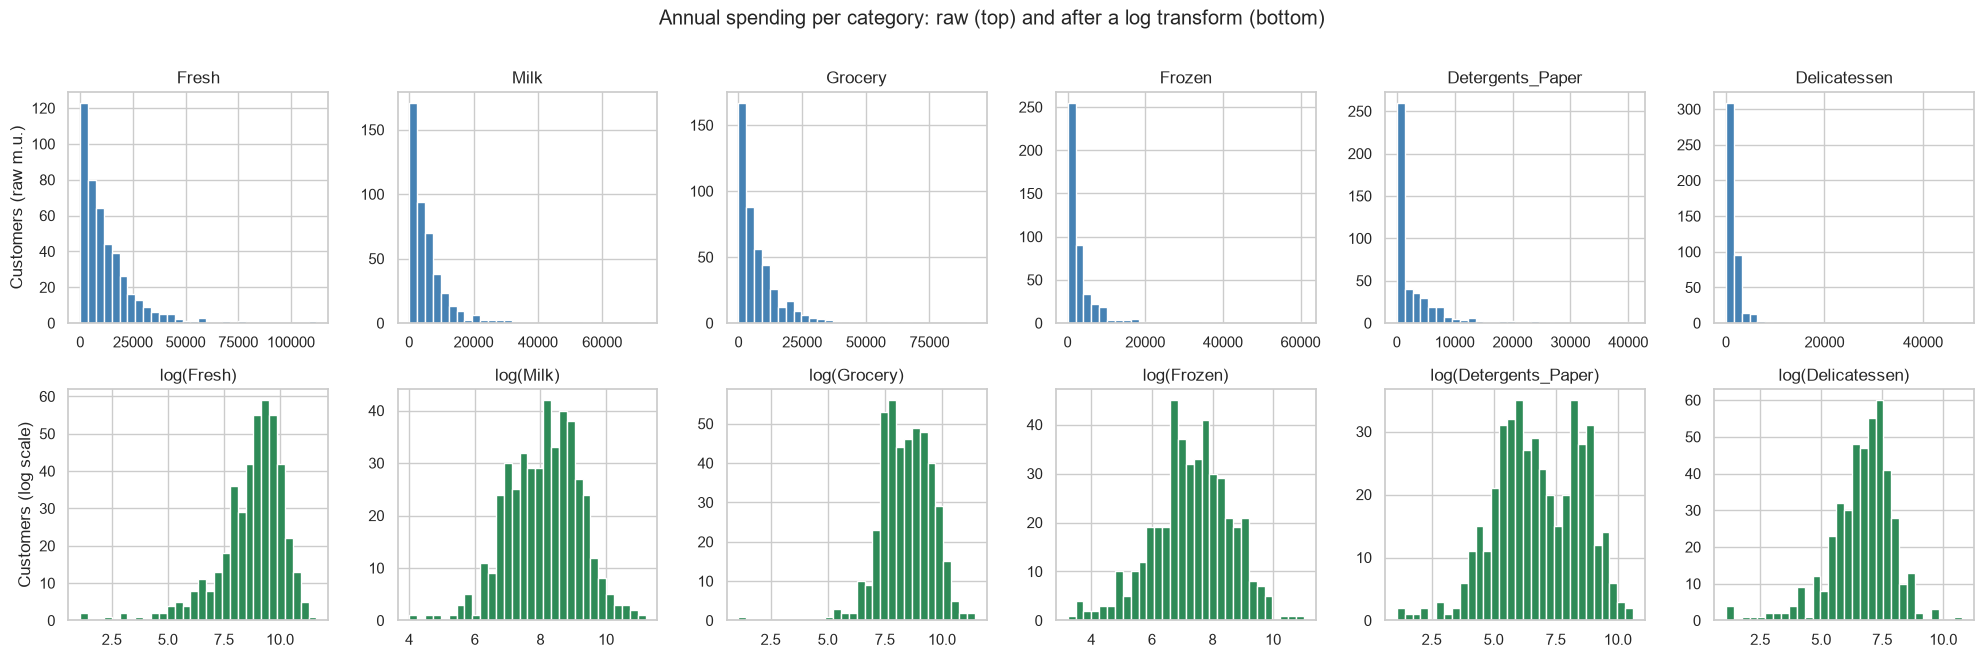

In [26]:
fig, axes = plt.subplots(2, 6, figsize=(20, 6.5))
for i, col in enumerate(SPEND):
    axes[0, i].hist(df[col], bins=30, color="steelblue", edgecolor="white")
    axes[0, i].set_title(col)
    axes[1, i].hist(np.log(df[col]), bins=30, color="seagreen", edgecolor="white")
    axes[1, i].set_title(f"log({col})")
axes[0, 0].set_ylabel("Customers (raw m.u.)")
axes[1, 0].set_ylabel("Customers (log scale)")
plt.suptitle("Annual spending per category: raw (top) and after a log transform (bottom)", y=1.01)
plt.tight_layout()
plt.show()

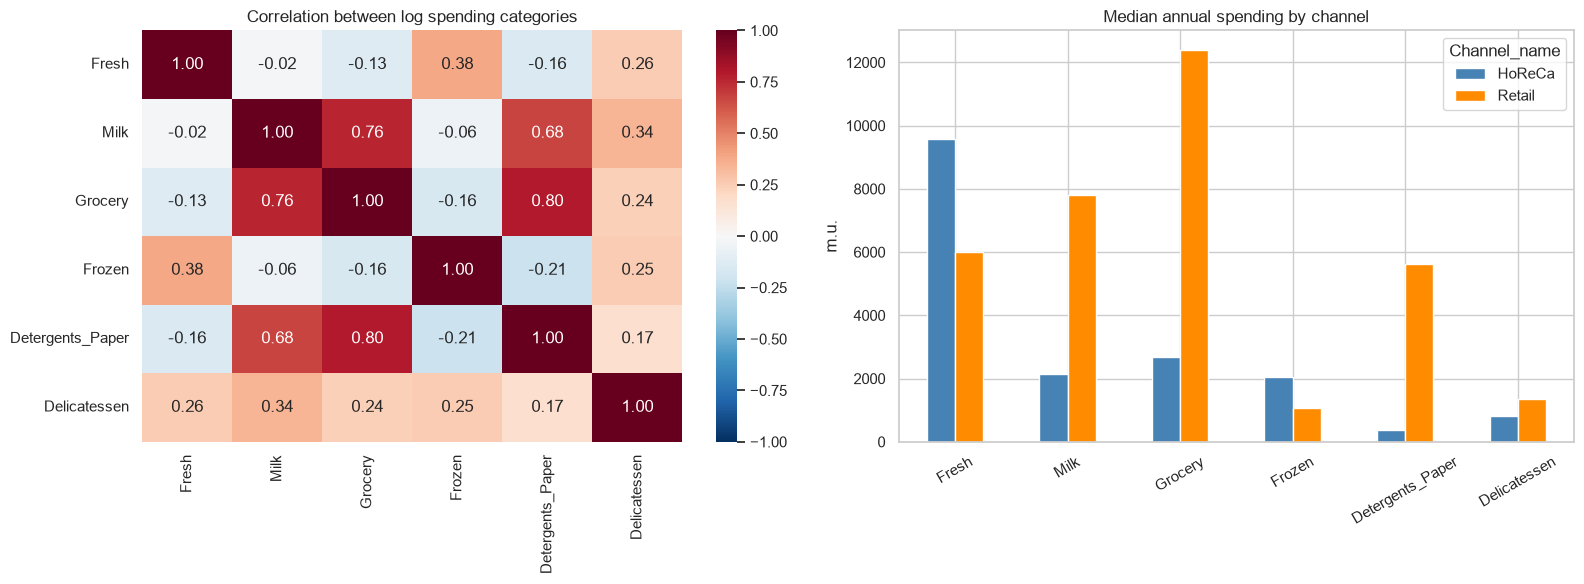

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.heatmap(np.log(df[SPEND]).corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, ax=axes[0])
axes[0].set_title("Correlation between log spending categories")

# Median spending by sales channel, as a first look at whether channel shapes behaviour
df.groupby("Channel_name")[SPEND].median().T.plot(kind="bar", ax=axes[1],
                                                    color=["steelblue", "darkorange"])
axes[1].set(title="Median annual spending by channel", ylabel="m.u.", xlabel="")
axes[1].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Observations:**

- the raw histograms are piled up near zero with long right tails; after a log transform each category is roughly bell-shaped, apart from a few very low values on the left
- **Grocery, Milk and Detergents_Paper move together** (log correlations 0.68–0.80), while Fresh and Frozen form a second, weaker pair (0.38). Fresh is almost uncorrelated with, or slightly opposed to, the grocery group
- by channel, HoReCa customers spend more on Fresh and Frozen, and Retail customers spend far more on Grocery, Milk and Detergents_Paper. Two broad buying patterns are already visible before any clustering

**Limitation of the data:** it records only total annual spend per category. There is no information on order frequency, margins, customer size or how spending changes over time, so the segments can only describe *what* customers buy and *how much*.

## 2. Data preparation

- **Variables clustered:** the six spending columns only. The task is to segment by *spending behaviour*. Channel and Region are nominal labels that would need special distance measures, so they are kept aside and used afterwards to describe and sanity-check the segments.
- **Log transform:** all six categories are heavily right-skewed. K-means and Ward clustering use squared Euclidean distance, so without a transform a handful of very large customers would dominate the result (this is tested in Section 9). Spending also differs between customers by *multiples* (one buys 10 times more than another), which a log scale treats sensibly. All values are at least 3 m.u., so the log is always defined.
- **Standardisation:** after the log, each category is scaled to mean 0 and standard deviation 1, so that no category counts more just because its numbers are bigger.
- **Small values kept:** the 39 customers with a category under 50 m.u. become low outliers on the log scale. They are real customers, so they are kept, and Section 9 checks that removing them does not change the conclusions.
- **No missing values or duplicates**, so no imputation or removal is needed.
- **PCA for plotting only:** a 2-D principal-component view is used to draw the clusters. All clustering uses the full six scaled columns.

In [28]:
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_log = np.log(df[SPEND])                       # log of spending (all values are >= 3, so log is defined)
X = StandardScaler().fit_transform(X_log)       # each category: mean 0, standard deviation 1

print("Prepared matrix:", X.shape)
print("Means after scaling:", X.mean(axis=0).round(2))
print("Std devs after scaling:", X.std(axis=0).round(2))

# 2-D view for plotting only (clustering always uses all 6 scaled columns)
pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(X)
X_2d = pca.transform(X)
print("Share of variance shown by the 2-D PCA view:", pca.explained_variance_ratio_.sum().round(3))

Prepared matrix: (440, 6)
Means after scaling: [-0. -0. -0.  0.  0.  0.]
Std devs after scaling: [1. 1. 1. 1. 1. 1.]
Share of variance shown by the 2-D PCA view: 0.711


The 2-D PCA view shows about 71% of the variation, so it is a fair but not perfect picture. Points that overlap in the plots may be further apart in six dimensions.

## 3. Cluster tendency: is there any cluster structure to find?

Clustering algorithms always return clusters, even for random data, so we first check whether the data has a tendency to cluster.

- **Hopkins statistic H** (Lawson & Jurs, 1990): compares distances between real customers with distances from randomly placed points. H ≈ 0.5 means no structure; values near 1 mean clustered data. It is repeated 50 times with different random samples to show how much it varies.
- **A fairer reference:** data that is skewed or correlated also scores above 0.5 without real clusters. So we also compute H for a single Gaussian "blob" with the same means and correlations as our data. Real cluster structure should score clearly above this blob.

In [29]:
from sklearn.neighbors import NearestNeighbors

def hopkins(data, seed, sample_frac=0.1):
    """Hopkins statistic H: about 0.5 = no cluster structure, close to 1 = clustered."""
    rng = np.random.default_rng(seed)
    n, d = data.shape
    m = int(sample_frac * n)
    nn = NearestNeighbors(n_neighbors=2).fit(data)
    real = data[rng.choice(n, m, replace=False)]
    w = nn.kneighbors(real, 2)[0][:, 1]                       # real point -> nearest other real point
    uniform = rng.uniform(data.min(axis=0), data.max(axis=0), (m, d))
    u = nn.kneighbors(uniform, 1)[0][:, 0]                    # random point -> nearest real point
    return u.sum() / (u.sum() + w.sum())

def hopkins_repeated(data, repeats=50):
    values = [hopkins(data, seed) for seed in range(repeats)]
    return np.mean(values), np.std(values)

# Reference: one Gaussian "blob" with the same means and correlations as our data.
# It has no clusters, so it shows what H looks like for correlated data without clusters.
rng = np.random.default_rng(RANDOM_STATE)
gauss = rng.multivariate_normal(X.mean(axis=0), np.cov(X.T), size=len(X))

rows = []
for name, data in [("Raw spending (scaled, no log)", StandardScaler().fit_transform(df[SPEND])),
                   ("Log spending (scaled) - used for clustering", X),
                   ("Reference: one Gaussian blob, same correlations", gauss)]:
    mean, std = hopkins_repeated(data)
    rows.append({"Data": name, "Hopkins H (mean of 50)": mean, "std": std})
pd.DataFrame(rows).set_index("Data").round(3)

,Hopkins H (mean of 50),std
Data,,
"Raw spending (scaled, no log)",0.937,0.014
Log spending (scaled) - used for clustering,0.803,0.014
"Reference: one Gaussian blob, same correlations",0.729,0.013


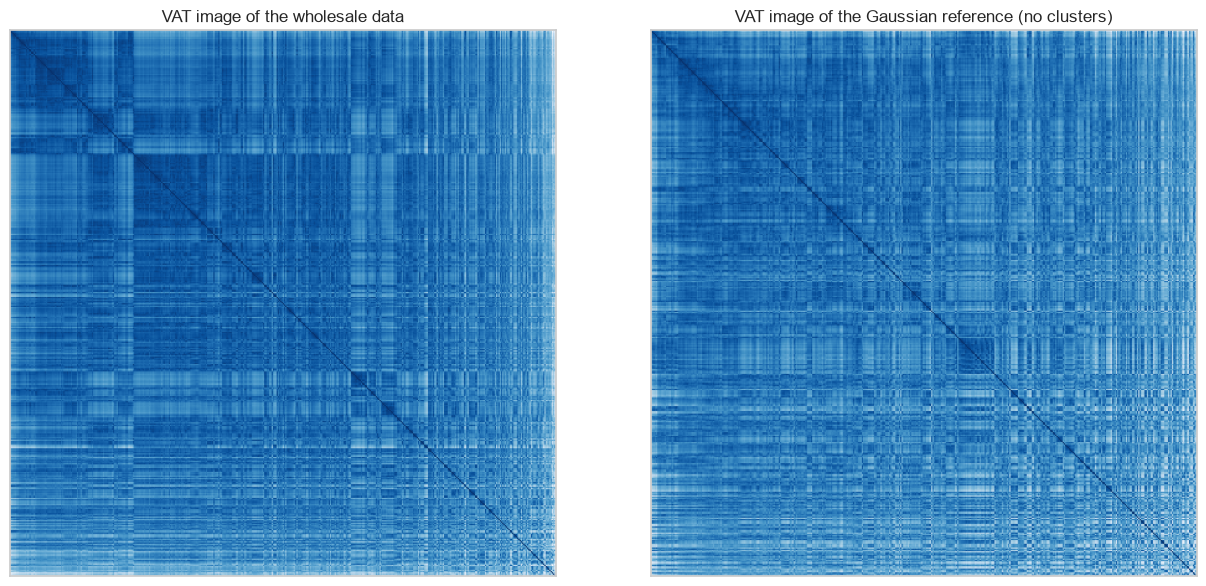

In [30]:
from scipy.spatial.distance import pdist, squareform

def vat_order(D):
    """VAT: reorders points so that similar points sit next to each other."""
    n = D.shape[0]
    order = [int(np.argmax(D.max(axis=1)))]
    remaining = set(range(n)) - set(order)
    min_dist = D[order[0]].copy()
    while remaining:
        rem = np.array(sorted(remaining))
        nxt = rem[np.argmin(min_dist[rem])]
        order.append(nxt)
        remaining.remove(nxt)
        min_dist = np.minimum(min_dist, D[nxt])
    return order

D = squareform(pdist(X))                  # distance between every pair of customers
order = vat_order(D)
Dg = squareform(pdist(gauss))
og = vat_order(Dg)

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
axes[0].imshow(D[np.ix_(order, order)], cmap="Blues_r")
axes[0].set_title("VAT image of the wholesale data")
axes[1].imshow(Dg[np.ix_(og, og)], cmap="Blues_r")
axes[1].set_title("VAT image of the Gaussian reference (no clusters)")
for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

**Cluster tendency, interpretation:**

- on the raw data H = 0.94, but this is inflated by the skew: the few very large customers stretch the range, leaving empty space where random points land far from any real customer
- on the prepared (log, scaled) data H = 0.80 ± 0.01, well above 0.5, so the data is **not uniformly random**
- however, a single correlated Gaussian blob already reaches H = 0.73. The gap (0.80 vs 0.73) shows **real but moderate** cluster tendency
- the **VAT image** (visual assessment of cluster tendency; Bezdek & Hathaway, 2002) reorders customers so that similar ones sit together; dark blocks on the diagonal are candidate clusters. The wholesale image shows a few large, faint blocks (strongest at the top-left), while the Gaussian reference shows almost none. The blocks are not sharply separated

**Conclusion:** there is enough structure to justify clustering, but the groups overlap. We should expect moderate quality scores and treat segment boundaries as fuzzy rather than sharp.

## 4. Partitioning: k-means

K-means (MacQueen, 1967) splits customers into *k* groups so that each customer is close to its group's centre (centroid). It suits this data after the log transform (roughly symmetric, continuous features) and gives directly readable centroids. It needs *k* chosen in advance, so we compare k = 2 to 8 using four criteria:

- **Elbow (inertia):** within-cluster spread. Look for where adding clusters stops helping much
- **Silhouette** (Rousseeuw, 1987): how much closer customers are to their own cluster than to the next one (−1 to 1; higher is better)
- **Davies–Bouldin** (lower is better) and **Calinski–Harabasz** (higher is better): compactness against separation
- **Stability:** re-cluster bootstrap samples of the customers and measure agreement with the full-data solution using the adjusted Rand index (ARI). Segments that change with the sample are not useful for business decisions

Each k-means run uses 20 random starts (`n_init=20`) to avoid a poor local solution.

In [31]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score, adjusted_rand_score

def bootstrap_stability(make_labels, data, repeats=30, seed=RANDOM_STATE):
    """Average agreement (ARI) between the full-data clustering and clusterings of bootstrap samples."""
    full = make_labels(data)
    rng = np.random.default_rng(seed)
    scores = []
    for _ in range(repeats):
        idx = np.unique(rng.choice(len(data), len(data), replace=True))   # customers in this bootstrap sample
        scores.append(adjusted_rand_score(full[idx], make_labels(data[idx])))
    return np.mean(scores)

def quality(labels, data=X):
    """Silhouette, Davies-Bouldin and Calinski-Harabasz, on non-noise points only (label -1 = noise)."""
    keep = labels != -1
    if len(np.unique(labels[keep])) < 2:
        return {"Silhouette": np.nan, "Davies_Bouldin": np.nan, "Calinski_Harabasz": np.nan}
    return {"Silhouette": silhouette_score(data[keep], labels[keep]),
            "Davies_Bouldin": davies_bouldin_score(data[keep], labels[keep]),
            "Calinski_Harabasz": calinski_harabasz_score(data[keep], labels[keep])}

In [32]:
km_rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit(X)
    make = lambda d: KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE).fit_predict(d)
    km_rows.append({"k": k, "Inertia": km.inertia_,
                    **quality(km.labels_),
                    "Stability (bootstrap ARI)": bootstrap_stability(make, X),
                    "Smallest cluster": np.bincount(km.labels_).min()})
km_table = pd.DataFrame(km_rows).set_index("k")
km_table.round(3)

,Inertia,Silhouette,Davies_Bouldin,Calinski_Harabasz,Stability (bootstrap ARI),Smallest cluster
k,,,,,,
2,1847.980,0.290,1.353,187.721,0.914,188
3,1558.047,0.258,1.346,151.733,0.816,81
4,1391.926,0.188,1.542,130.314,0.654,61
5,1271.309,0.191,1.489,117.080,0.581,54
6,1178.576,0.192,1.452,107.631,0.645,18
7,1090.520,0.189,1.424,102.539,0.683,23
8,1026.923,0.194,1.391,96.940,0.662,11


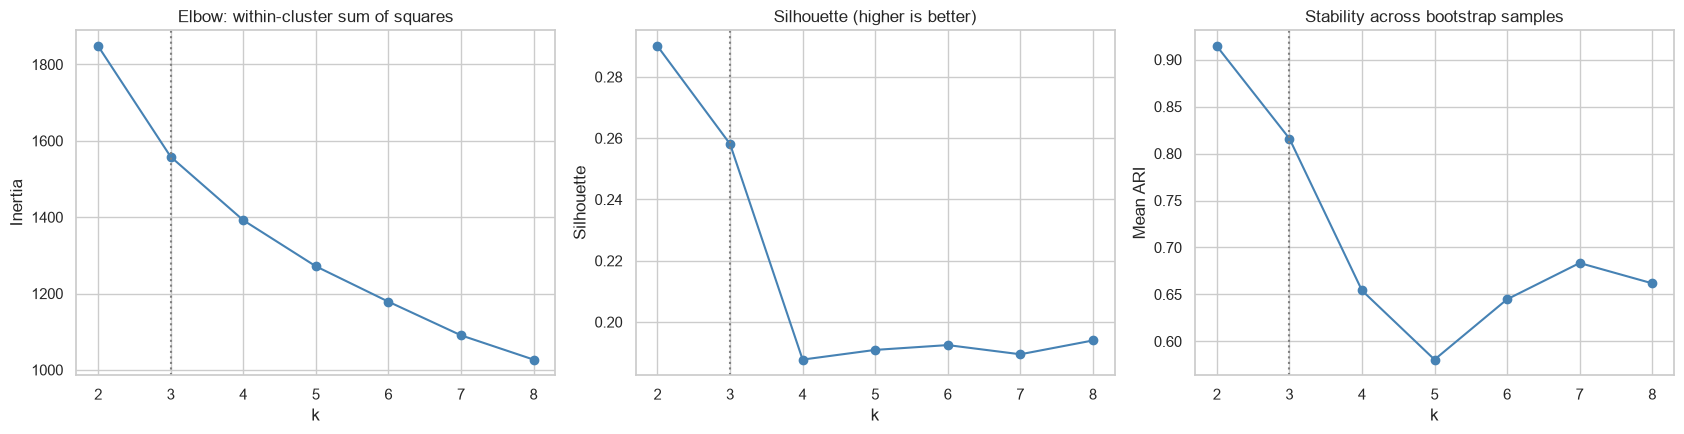

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
km_table["Inertia"].plot(marker="o", ax=axes[0], color="steelblue")
axes[0].set(title="Elbow: within-cluster sum of squares", ylabel="Inertia")
km_table["Silhouette"].plot(marker="o", ax=axes[1], color="steelblue")
axes[1].set(title="Silhouette (higher is better)", ylabel="Silhouette")
km_table["Stability (bootstrap ARI)"].plot(marker="o", ax=axes[2], color="steelblue")
axes[2].set(title="Stability across bootstrap samples", ylabel="Mean ARI")
for ax in axes:
    ax.axvline(3, color="grey", linestyle=":")
plt.tight_layout()
plt.show()

**Choosing k:**

- **k = 2** has the best silhouette (0.290), the best Calinski–Harabasz score (188) and the highest stability (0.91). Statistically it is the strongest solution
- **k = 3** is close behind: silhouette 0.258, the best (lowest) Davies–Bouldin score (1.35) and stability still high (0.82). Its smallest cluster has 81 customers, which is a usable segment size
- from **k = 4** onwards silhouette drops to about 0.19 and stability falls to 0.58–0.68, so the extra clusters are not reliable
- the elbow plot has no sharp bend, which matches the "moderate tendency" finding in Section 3

**Decision: k = 3.** It costs little in quality compared with k = 2, remains stable, and is more useful for the business. Section 9 shows it simply splits one of the two k = 2 groups into two meaningfully different buying patterns. All silhouettes are below 0.3, which is usually read as weak structure (Kaufman & Rousseeuw, 1990), so the segments should be read as tendencies.

In [34]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit(X)
labels_km = kmeans.labels_
print("Customers per k-means cluster:", np.bincount(labels_km))

Customers per k-means cluster: [211 148  81]


## 5. Hierarchical clustering

Agglomerative clustering starts with every customer on its own and repeatedly merges the two closest groups. The result is a tree (dendrogram) that can be cut at any number of clusters, so *k* need not be fixed beforehand. The **linkage** defines "closest". We compare four common linkages at k = 3:

In [35]:
from sklearn.cluster import AgglomerativeClustering

link_rows = []
for method in ["ward", "complete", "average", "single"]:
    labels = AgglomerativeClustering(n_clusters=K, linkage=method).fit_predict(X)
    link_rows.append({"Linkage": method, **quality(labels),
                      "Cluster sizes": sorted(np.bincount(labels).tolist(), reverse=True)})
pd.DataFrame(link_rows).set_index("Linkage").round(3)

,Silhouette,Davies_Bouldin,Calinski_Harabasz,Cluster sizes
Linkage,,,,
ward,0.235,1.409,136.301,"[234, 116, 90]"
complete,0.137,2.484,23.080,"[311, 127, 2]"
average,0.551,0.301,9.465,"[438, 1, 1]"
single,0.519,0.330,8.371,"[438, 1, 1]"


**Linkage comparison:**

- **single and average linkage** give 438 / 1 / 1. They "chain" almost everyone into one group and split off two extreme customers. Their high silhouette (about 0.52–0.55) is misleading: it comes from isolating two outliers, not from a useful segmentation. This shows why a quality score must be read together with cluster sizes
- **complete linkage** also splits off a tiny group of 2
- **Ward linkage** (Ward, 1963), which merges the groups whose union increases within-cluster variance least, gives balanced clusters (234 / 116 / 90) and the best scores among usable solutions. Ward is used from here on

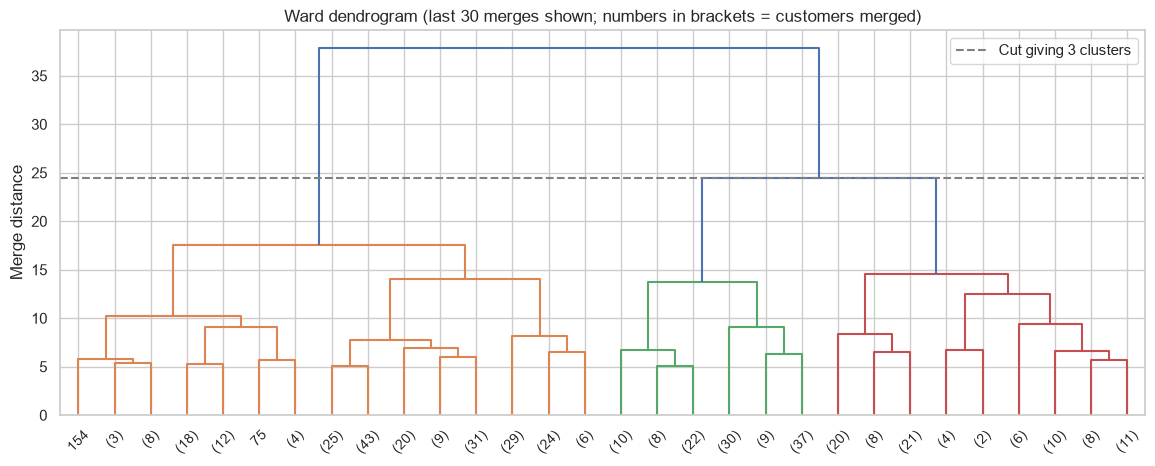

Customers per Ward cluster: [234  90 116]
Agreement with k-means (ARI): 0.687


In [36]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X, method="ward")
plt.figure(figsize=(14, 5))
dendrogram(Z, truncate_mode="lastp", p=30, color_threshold=Z[-K + 1, 2], no_labels=False)
plt.axhline(Z[-K + 1, 2], color="grey", linestyle="--", label=f"Cut giving {K} clusters")
plt.title("Ward dendrogram (last 30 merges shown; numbers in brackets = customers merged)")
plt.ylabel("Merge distance")
plt.legend()
plt.show()

labels_ward = AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(X)
print("Customers per Ward cluster:", np.bincount(labels_ward))
print("Agreement with k-means (ARI):", round(adjusted_rand_score(labels_km, labels_ward), 3))

**Dendrogram:**

- the highest merge (distance about 38) separates the data into two large branches, and the next (about 24.5) splits the right-hand branch in two. This supports k = 2 as the main division and k = 3 as the next sensible level, which agrees with the k-means analysis
- below the cut there are many merges at similar heights with no long empty gaps, so the data has no further clear-cut groups
- Ward and k-means agree moderately (ARI 0.69): the main structure is shared, but customers near the boundaries are assigned differently

## 6. Density-based clustering

Density-based methods find clusters as dense regions separated by sparse ones, and they label points in sparse regions as **noise** rather than forcing them into a cluster. They can find clusters of any shape and do not need *k*.

- **DBSCAN** (Ester et al., 1996) has two settings. `min_samples` is set to 12 (twice the number of dimensions, a common rule of thumb), and `eps` (the neighbourhood radius) is read from the k-distance plot, where the curve starts to bend upwards
- **HDBSCAN** (Campello et al., 2013) removes the need to pick `eps` by considering all densities and keeping the most persistent clusters. It needs only a minimum cluster size

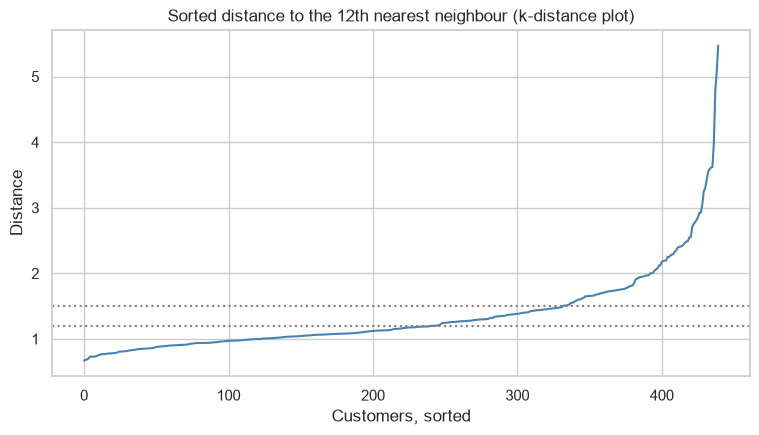

In [37]:
MIN_SAMPLES = 2 * X.shape[1]      # common rule of thumb: twice the number of dimensions (12)
kdist = np.sort(NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)[0][:, -1])

plt.figure(figsize=(9, 4.5))
plt.plot(kdist, color="steelblue")
for eps in [1.2, 1.5]:
    plt.axhline(eps, color="grey", linestyle=":")
plt.title(f"Sorted distance to the {MIN_SAMPLES}th nearest neighbour (k-distance plot)")
plt.xlabel("Customers, sorted")
plt.ylabel("Distance")
plt.show()

In [38]:
from sklearn.cluster import DBSCAN, HDBSCAN

db_rows = []
for eps in [0.8, 1.0, 1.2, 1.5, 1.8]:
    labels = DBSCAN(eps=eps, min_samples=MIN_SAMPLES).fit_predict(X)
    db_rows.append({"Method": "DBSCAN", "Setting": f"eps={eps}",
                    "Clusters": len(set(labels)) - (-1 in labels),
                    "Noise %": 100 * (labels == -1).mean(),
                    "Cluster sizes": sorted(np.bincount(labels[labels >= 0]).tolist(), reverse=True)})
# copy=True: HDBSCAN works on a copy of X (setting it also stops a scikit-learn warning)
for mcs in [10, 15, 20, 30]:
    labels = HDBSCAN(min_cluster_size=mcs, copy=True).fit_predict(X)
    db_rows.append({"Method": "HDBSCAN", "Setting": f"min_cluster_size={mcs}",
                    "Clusters": len(set(labels)) - (-1 in labels),
                    "Noise %": 100 * (labels == -1).mean(),
                    "Cluster sizes": sorted(np.bincount(labels[labels >= 0]).tolist(), reverse=True)})
pd.DataFrame(db_rows).set_index(["Method", "Setting"]).round(1)

Clusters  Noise % Cluster sizes
Method  Setting                                             
DBSCAN  eps=0.8                     2     78.4      [50, 45]
        eps=1.0                     1     40.7         [261]
        eps=1.2                     1     22.5         [341]
        eps=1.5                     1     11.4         [390]
        eps=1.8                     1      5.9         [414]
HDBSCAN min_cluster_size=10         2     79.1      [49, 43]
        min_cluster_size=15         2     84.3      [37, 32]
        min_cluster_size=20         2     84.3      [35, 34]
        min_cluster_size=30         2     82.3      [42, 36]

**Observations:**

- the k-distance curve bends gradually between about 1.2 and 1.5, with no sharp knee, which is another sign that there are no clear density gaps
- across every `eps` from 1.0 to 1.8, **DBSCAN finds only one cluster** plus noise. Only at a small `eps` (0.8) does it find two small groups, and then it labels 78% of customers as noise
- **HDBSCAN** consistently finds two small dense cores of about 30–50 customers each and labels 79–85% of customers as noise, whatever the minimum cluster size

So the density-based methods agree with the cluster-tendency results: the customers form **one continuous cloud** with a denser core and sparser edges, not separate dense groups. We keep DBSCAN with `eps = 1.2` (at the start of the bend) and HDBSCAN with a minimum size of 15 for the comparison.

In [39]:
EPS = 1.2
labels_db = DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X)
labels_hdb = HDBSCAN(min_cluster_size=15, copy=True).fit_predict(X)

# Who are DBSCAN's "noise" customers? Compare their spending with the dense core.
noise = labels_db == -1
print("Customers labelled noise:", noise.sum())
print("Retail share - noise:", round(100 * (df.loc[noise, "Channel"] == 2).mean(), 1), "%",
      "  core:", round(100 * (df.loc[~noise, "Channel"] == 2).mean(), 1), "%")
print("Customers with a category < 50 m.u. - noise:", (df.loc[noise, SPEND] < 50).any(axis=1).sum(),
      "  core:", (df.loc[~noise, SPEND] < 50).any(axis=1).sum())
pd.DataFrame({"Noise customers (median m.u.)": df.loc[noise, SPEND].median(),
              "Core customers (median m.u.)": df.loc[~noise, SPEND].median()}).round(0)

Customers labelled noise: 99
Retail share - noise: 36.4 %   core: 31.1 %
Customers with a category < 50 m.u. - noise: 35   core: 4


,Noise customers (median m.u.),Core customers (median m.u.)
Fresh,3097.0,9203.0
Milk,5164.0,3328.0
Grocery,7854.0,4172.0
Frozen,661.0,1777.0
Detergents_Paper,813.0,820.0
Delicatessen,522.0,1009.0


**Who does DBSCAN call noise?** The 99 noise customers (22.5%) are mostly the sparse "edge" of the cloud. Compared with the dense core they spend less on Fresh and Frozen and more on Grocery and Milk (medians: Fresh 3,097 vs 9,203 m.u.; Grocery 7,854 vs 4,172 m.u.). They are slightly more often Retail customers (36% vs 31%), and they include 35 of the 39 very-low-spending customers. DBSCAN therefore treats the typical fresh-food buyer as the dense core, while grocery-oriented and very small buyers are more spread out. That is useful for spotting unusual customers, but it is not a segmentation that covers everyone.

## 7. Comparing the three approaches

All methods are compared on the same prepared data. Quality scores are computed only on non-noise customers, so for the density methods they describe a small, easy subset.

- **Internal quality:** silhouette, Davies–Bouldin, Calinski–Harabasz
- **Stability:** bootstrap ARI, as in Section 4
- **Agreement:** ARI with the k-means solution, and ARI with the sales channel. Channel is *not* a ground truth, but a sensible segmentation should relate to it, since HoReCa and Retail buy differently

In [40]:
# One small function per method, so the bootstrap can re-run each method on a resample
def run_kmeans(d):
    return KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit_predict(d)

def run_ward(d):
    return AgglomerativeClustering(n_clusters=K, linkage="ward").fit_predict(d)

def run_dbscan(d):
    return DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(d)

def run_hdbscan(d):
    return HDBSCAN(min_cluster_size=15, copy=True).fit_predict(d)

methods = {"K-means (k=3)": (labels_km, run_kmeans),
           "Hierarchical, Ward (k=3)": (labels_ward, run_ward),
           f"DBSCAN (eps={EPS})": (labels_db, run_dbscan),
           "HDBSCAN (min size 15)": (labels_hdb, run_hdbscan)}

cmp_rows = []
for name, (labels, make) in methods.items():
    cmp_rows.append({"Method": name,
                     "Clusters": len(set(labels)) - (-1 in labels),
                     "Noise %": 100 * (labels == -1).mean(),
                     **quality(labels),
                     "Stability (bootstrap ARI)": bootstrap_stability(make, X),
                     "ARI with k-means": adjusted_rand_score(labels_km, labels),
                     "ARI with sales channel": adjusted_rand_score(df["Channel"], labels)})
comparison = pd.DataFrame(cmp_rows).set_index("Method")
comparison.round(3)

,Clusters,Noise %,Silhouette,Davies_Bouldin,Calinski_Harabasz,Stability (bootstrap ARI),ARI with k-means,ARI with sales channel
Method,,,,,,,,
K-means (k=3),3,0.000,0.258,1.346,151.733,0.816,1.000,0.341
"Hierarchical, Ward (k=3)",3,0.000,0.235,1.409,136.301,0.610,0.687,0.412
DBSCAN (eps=1.2),1,22.500,NaN,NaN,NaN,0.703,0.102,0.015
HDBSCAN (min size 15),2,84.318,0.582,0.620,159.985,0.555,0.008,0.052


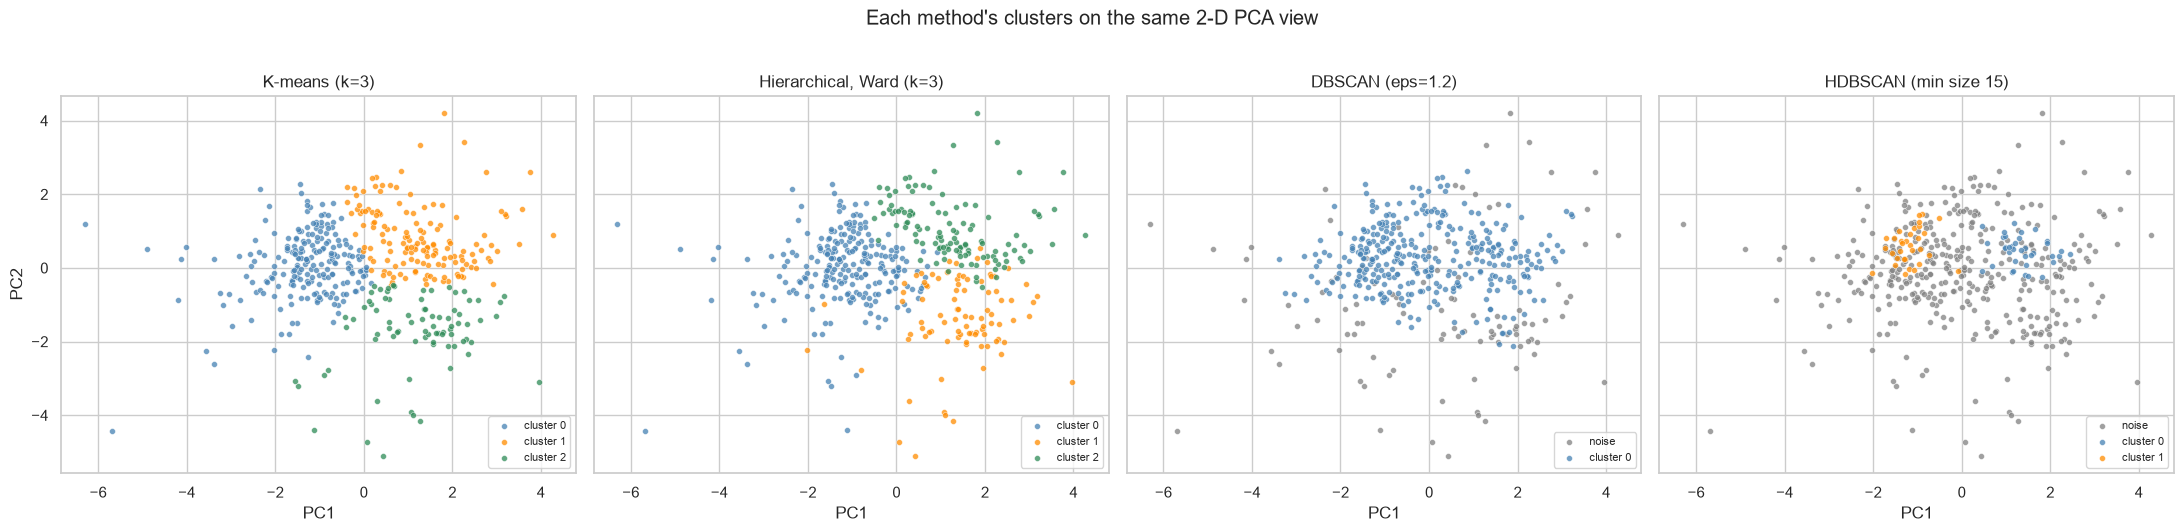

In [41]:
fig, axes = plt.subplots(1, 4, figsize=(22, 5.2), sharex=True, sharey=True)
for ax, (name, (labels, _)) in zip(axes, methods.items()):
    for c in sorted(set(labels)):
        pts = labels == c
        colour = NOISE_COLOUR if c == -1 else CLUSTER_COLOURS[c % 3]
        ax.scatter(X_2d[pts, 0], X_2d[pts, 1], s=18, alpha=0.75, color=colour,
                   label="noise" if c == -1 else f"cluster {c}", edgecolor="white", linewidth=0.4)
    ax.set_title(name)
    ax.set_xlabel("PC1")
    ax.legend(fontsize=8, loc="lower right")
axes[0].set_ylabel("PC2")
plt.suptitle("Each method's clusters on the same 2-D PCA view", y=1.02)
plt.tight_layout()
plt.show()

**Comparison of quality and interpretability:**

| | Partitioning (k-means, k=3) | Hierarchical (Ward, k=3) | Density-based (DBSCAN / HDBSCAN) |
|---|---|---|---|
| Quality | Silhouette 0.258, best CH among full solutions | Silhouette 0.235, slightly worse on every score | DBSCAN: only one cluster, so quality cannot be scored. HDBSCAN: silhouette 0.586, but only on the 15% of customers it clusters |
| Stability | **0.82**, highest | 0.61 | 0.70 / 0.57 |
| Coverage | Every customer assigned | Every customer assigned | 22.5% / 85% of customers left as noise |
| Interpretability | **High**: each centroid is a readable spending profile | Good: the dendrogram shows the nested two-then-three structure | Low for segmentation; useful for flagging unusual customers |
| Relation to channel | ARI 0.34 | ARI 0.41 | ARI 0.02 / 0.05 |
| Main assumption | Roughly round clusters of similar spread; *k* chosen | Merge rule (linkage) chosen; early merges cannot be undone | Clusters separated by low-density gaps, which this data lacks |

**Interpretation:**

- **k-means is the most useful approach here.** It is the most stable, covers every customer, and its centroids translate directly into spending profiles. Its weakness is that it must place borderline customers in a cluster even though the groups overlap
- **Ward** finds broadly the same structure (ARI 0.69 with k-means) and relates slightly more closely to channel, but it is less stable, because one early merge decision can move a whole branch
- **Density-based methods** are not suitable for segmenting this data. That is not a flaw in the methods: the data has no density gaps between groups, which they correctly report. HDBSCAN's high silhouette is a by-product of clustering only the tightest 15% of customers
- no method reaches a silhouette above 0.3 on the full data, consistent with the moderate cluster tendency in Section 3

**Decision:** use the k-means segments (k = 3) for naming and recommendations.

## 8. Naming the segments and recommendations

Segments are described in the original monetary units (medians, which are robust to the skew), by **basket mix** (each category's share of a customer's total spend), and by channel and region make-up.

In [42]:
df["cluster"] = labels_km
medians = df.groupby("cluster")[SPEND].median()
medians["Total (median)"] = df.assign(Total=df[SPEND].sum(axis=1)).groupby("cluster")["Total"].median()
medians["Customers"] = df["cluster"].value_counts().sort_index()
medians.round(0).astype(int)

,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen,Total (median),Customers
cluster,,,,,,,,
0,9612,1596,2147,2121,274,686,18480,211
1,12166,7146,9880,2019,3350,1988,45620,148
2,1454,6264,10487,388,4196,436,27289,81


In [43]:
# Basket mix: each category's share of the customer's total spend (median per cluster)
share = df[SPEND].div(df[SPEND].sum(axis=1), axis=0).assign(cluster=df["cluster"])
basket = (100 * share.groupby("cluster")[SPEND].median()).round(1)

channel_mix = pd.crosstab(df["cluster"], df["Channel_name"], normalize="index").mul(100).round(1)
region_mix = pd.crosstab(df["cluster"], df["Region_name"], normalize="index").mul(100).round(1)

print("Median share of total spend (%):")
display(basket)
print("Sales channel within each cluster (%):")
display(channel_mix)
print("Region within each cluster (%):")
display(region_mix)

Median share of total spend (%):


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicatessen
cluster,,,,,,
0,53.3,8.2,11.8,11.9,1.6,3.8
1,28.0,19.2,26.2,4.8,8.9,4.6
2,7.1,23.8,40.4,1.6,16.3,1.8


Sales channel within each cluster (%):


Channel_name,HoReCa,Retail
cluster,,
0,98.6,1.4
1,38.5,61.5
2,40.7,59.3


Region within each cluster (%):


Region_name,Lisbon,Oporto,Other
cluster,,,
0,19.0,12.3,68.7
1,15.5,7.4,77.0
2,17.3,12.3,70.4


In [44]:
# Names are assigned from the profiles above, not by cluster number,
# so they stay correct even if k-means numbers the clusters differently.
c_fresh = basket["Fresh"].idxmax()                       # biggest share of spend on fresh food
c_grocery = basket["Grocery"].idxmax()                   # biggest share on grocery
c_large = [c for c in range(K) if c not in (c_fresh, c_grocery)][0]
SEGMENT_NAMES = {int(c_fresh): "Fresh-food caterers",
                 int(c_grocery): "Grocery and household specialists",
                 int(c_large): "High-volume all-rounders"}
df["segment"] = df["cluster"].map(SEGMENT_NAMES)
print(SEGMENT_NAMES)
df["segment"].value_counts()

{0: 'Fresh-food caterers', 2: 'Grocery and household specialists', 1: 'High-volume all-rounders'}


segment
Fresh-food caterers                  211
High-volume all-rounders             148
Grocery and household specialists     81
Name: count, dtype: int64

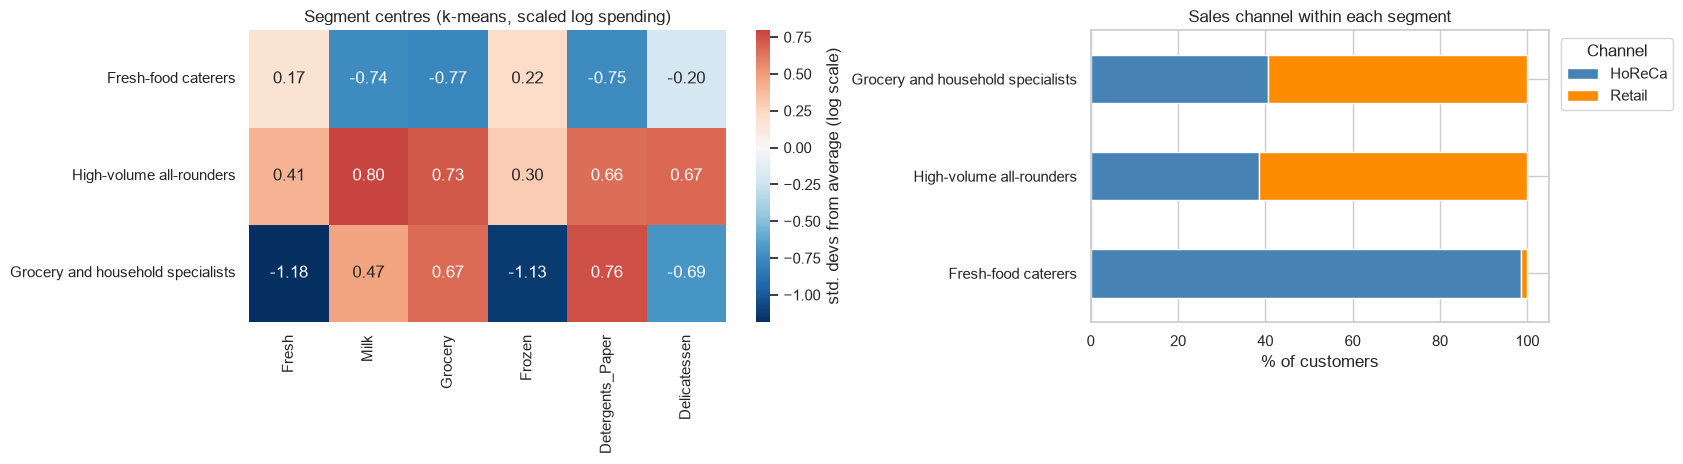

In [45]:
# Cluster centres on the scaled log scale: positive = above the average customer
centres = pd.DataFrame(kmeans.cluster_centers_, columns=SPEND).rename(index=SEGMENT_NAMES)
fig, axes = plt.subplots(1, 2, figsize=(17, 4.8), gridspec_kw={"width_ratios": [1.3, 1]})
sns.heatmap(centres, annot=True, fmt=".2f", cmap="RdBu_r", center=0, ax=axes[0],
            cbar_kws={"label": "std. devs from average (log scale)"})
axes[0].set(title="Segment centres (k-means, scaled log spending)", ylabel="")

channel_mix.rename(index=SEGMENT_NAMES).plot(kind="barh", stacked=True, ax=axes[1], color=["steelblue", "darkorange"], edgecolor="white")
axes[1].set(title="Sales channel within each segment", xlabel="% of customers", ylabel="")
axes[1].legend(title="Channel", loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

**Segment names and spending habits:**

**1. Fresh-food caterers** (211 customers, 48%)
- spend is dominated by fresh produce: about **53% of a typical customer's spend** is Fresh and 12% is Frozen, with only around 2% on Detergents_Paper
- below-average spending on Milk, Grocery and Detergents_Paper (centroid about −0.75 standard deviations on each)
- moderate total spend (median 18,480 m.u.), the smallest of the three segments
- **98.6% are HoReCa** customers: hotels, restaurants and cafés buying ingredients for daily cooking

**2. High-volume all-rounders** (148 customers, 34%)
- above average in **every** category, with the highest median Fresh (12,166 m.u.) and Delicatessen (1,988 m.u.) spending of any segment
- largest total spend by far (median **45,620 m.u.**, about 2.5 times the caterers)
- a broad basket: 28% Fresh, 26% Grocery, 19% Milk
- mixed channel (62% Retail, 38% HoReCa): large shops and larger restaurants or hotels that buy a full range

**3. Grocery and household specialists** (81 customers, 18%)
- spend concentrates on packaged goods: **40% Grocery, 24% Milk and 16% Detergents_Paper**
- very little Fresh (7%) or Frozen (2%); their centroid is more than one standard deviation below average on both
- mid-range total spend (median 27,289 m.u.)
- mostly Retail (59%): shops and minimarkets selling packaged and household goods

Region is spread similarly across all three segments (69–77% "Other"), so **segments reflect what customers buy, not where they are**.

### Recommendations: serving each segment differently

| Segment | What they need | Suggested actions |
|---|---|---|
| **Fresh-food caterers** | Reliable, frequent supply of perishable goods | Frequent (e.g. daily or early-morning) deliveries with strong cold-chain handling; standing orders for staple fresh items; freshness or quality guarantees; cross-sell kitchen and cleaning supplies as small add-ons, since they buy little in those categories today |
| **High-volume all-rounders** | Convenience and value across a wide range | Assign key-account managers; offer volume-based (tiered) pricing and consolidated mixed deliveries; promote premium and delicatessen lines, where they spend most; priority service, as they generate the most revenue per customer |
| **Grocery and household specialists** | Low prices on non-perishable bulk goods | Fewer, larger scheduled deliveries (the goods keep, so delivery costs can be cut); case or pallet discounts on grocery, milk and detergents; consider trialling a small range of fresh or frozen lines to test demand, since they buy almost none from the distributor today (they may buy them elsewhere) |

**Proportionate use:** the segments overlap (silhouette 0.26), so these are *starting points*, not rules. Each change should be piloted with a sample of customers and its effect measured before full roll-out. Customers near segment boundaries may need a mix of approaches.

## 9. Sensitivity checks

Do the segments depend on preparation choices or on randomness?

In [46]:
sens_rows = []

# 1. No log transform: cluster the raw (only scaled) spending
raw_labels = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit_predict(
    StandardScaler().fit_transform(df[SPEND]))
sens_rows.append({"Variation": "No log transform (raw spending, scaled)",
                  "Cluster sizes": sorted(np.bincount(raw_labels).tolist(), reverse=True),
                  "ARI with main k-means": adjusted_rand_score(labels_km, raw_labels)})

# 2. Remove the 39 customers with a category under 50 m.u. (extreme after the log)
keep = ~(df[SPEND] < 50).any(axis=1)
X_keep = StandardScaler().fit_transform(np.log(df.loc[keep, SPEND]))
keep_labels = KMeans(n_clusters=K, n_init=20, random_state=RANDOM_STATE).fit_predict(X_keep)
sens_rows.append({"Variation": f"Drop {(~keep).sum()} customers with a category < 50 m.u.",
                  "Cluster sizes": sorted(np.bincount(keep_labels).tolist(), reverse=True),
                  "ARI with main k-means": adjusted_rand_score(labels_km[keep], keep_labels)})

# 3. Different random starts for k-means
seed_ari = [adjusted_rand_score(labels_km, KMeans(n_clusters=K, n_init=1, random_state=s).fit_predict(X))
            for s in range(20)]
sens_rows.append({"Variation": "20 single random starts (n_init=1)",
                  "Cluster sizes": "-",
                  "ARI with main k-means": np.mean(seed_ari)})
pd.DataFrame(sens_rows).set_index("Variation").round(3)

,Cluster sizes,ARI with main k-means
Variation,,
"No log transform (raw spending, scaled)","[393, 45, 2]",0.081
Drop 39 customers with a category < 50 m.u.,"[195, 104, 102]",0.749
20 single random starts (n_init=1),-,0.702


**Observations:**

- **Without the log transform** k-means produces clusters of 393 / 45 / 2. A handful of very large customers dominate, and the result barely matches the main segments (ARI 0.08). This confirms that the log transform is essential, not cosmetic
- **Removing the 39 very-low-spending customers** gives similar segments (ARI 0.75), so these outliers do not drive the result
- **A single random start** agrees with the main 20-start solution only moderately (ARI 0.70 on average), because different starts can settle in different local solutions. Using many starts, as we do, is therefore important

In [47]:
# How do the 3 segments relate to the k=2 solution? Does k=3 split one of the k=2 groups?
labels_k2 = KMeans(n_clusters=2, n_init=20, random_state=RANDOM_STATE).fit_predict(X)
pd.crosstab(df["segment"], labels_k2, rownames=["k=3 segment"], colnames=["k=2 cluster"])

k=2 cluster,0,1
k=3 segment,,
Fresh-food caterers,210,1
Grocery and household specialists,9,72
High-volume all-rounders,33,115


**k = 3 versus k = 2:** the Fresh-food caterers match one k = 2 cluster almost exactly (210 of 211). The other k = 2 cluster is split into the High-volume all-rounders and the Grocery and household specialists. So k = 3 does not invent a new structure; it divides the broad "non-fresh" group into two groups with clearly different volumes and basket mixes. This is why the slight drop in silhouette is acceptable.

## 10. Conclusions and limitations

**Conclusions**

- spending is highly skewed and is best analysed on a log scale; Grocery, Milk and Detergents_Paper form one buying pattern, and Fresh and Frozen another
- the data has **real but moderate cluster tendency** (Hopkins 0.80 against 0.73 for an unclustered reference). Segments overlap rather than being sharply separated
- **partitioning (k-means)** gives the best balance of quality, stability (0.82) and interpretability. Ward hierarchical clustering confirms the same nested structure. Density-based methods find only one dense cloud and are not suitable for segmenting this data
- three segments, **Fresh-food caterers, High-volume all-rounders, and Grocery and household specialists**, differ clearly in basket mix and volume and call for different service models

**Limitations**

- only annual spend per category is available, with no order frequency, margins, customer size or trends over time. Segments could change if these were added
- 440 customers from one distributor, with most in the "Other" region, so results may not generalise to other markets
- the segments overlap, so some customers are borderline and could reasonably belong to two segments
- clustering describes groups; it does not show that a recommended service change *will* raise sales. That needs a controlled pilot

## References

- Bezdek, J. C. & Hathaway, R. J. (2002). VAT: A tool for visual assessment of (cluster) tendency. *Proc. International Joint Conference on Neural Networks*, 2225–2230.
- Campello, R. J. G. B., Moulavi, D. & Sander, J. (2013). Density-based clustering based on hierarchical density estimates. *PAKDD 2013*, LNCS 7819, 160–172.
- Cardoso, M. (2014). *Wholesale customers* [Dataset]. UCI Machine Learning Repository.
- Ester, M., Kriegel, H.-P., Sander, J. & Xu, X. (1996). A density-based algorithm for discovering clusters in large spatial databases with noise. *KDD-96*, 226–231.
- Han, J., Kamber, M. & Pei, J. (2012). *Data Mining: Concepts and Techniques* (3rd ed.). Morgan Kaufmann. Chapter 10 (cluster analysis, including cluster tendency).
- Kaufman, L. & Rousseeuw, P. J. (1990). *Finding Groups in Data: An Introduction to Cluster Analysis*. Wiley.
- Lawson, R. G. & Jurs, P. C. (1990). New index for clustering tendency and its application to chemical problems. *Journal of Chemical Information and Computer Sciences*, 30(1), 36–41.
- MacQueen, J. (1967). Some methods for classification and analysis of multivariate observations. *Proc. 5th Berkeley Symposium on Mathematical Statistics and Probability*, 1, 281–297.
- Pedregosa, F. et al. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research*, 12, 2825–2830.
- Rousseeuw, P. J. (1987). Silhouettes: A graphical aid to the interpretation and validation of cluster analysis. *Journal of Computational and Applied Mathematics*, 20, 53–65.
- Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association*, 58(301), 236–244.